# Objetivos: 

 - Conectar com o STAC;
 - Pegar o NDVI do Sentinel;
 - Geras geometrias a partir dos pixels de alto NDVI;
 - Tudo deve ser parametrizado;


In [42]:
import numpy as np 
import rasterio as rio 
import pystac_client 
import matplotlib.pyplot as plt
from shapely.geometry import Point
from shapely.ops import unary_union
import geopandas as gpd

## Import Data

In [2]:
URL = 'https://data.inpe.br/bdc/stac/v1/' 
service = pystac_client.Client.open(URL)

In [17]:
import collections
search = service.search(
    collections=["S2_L2A-1"],
    # tile 22KFC
    query={"eo:cloud_cover": {"lt": 10}, 
            "tileId": {"eq": "22KFC"}},
    datetime="2024-08-04/2024-09-04",
    method = "POST"
)

/tmp/ipykernel_1958512/2441033890.py:2: PystacClientWarning: The requested method 'POST' is not advertised by any root catalog search link. Available methods: GET
  search = service.search(


#### Disponíveis

In [20]:
items = search.item_collection()
[item.id for item in items]

['S2B_MSIL2A_20240903T133149_N0511_R081_T22KFC_20240903T154050',
 'S2B_MSIL2A_20240831T132239_N0511_R038_T22KFC_20240831T152654',
 'S2A_MSIL2A_20240829T133141_N0511_R081_T22KFC_20240829T184509',
 'S2B_MSIL2A_20240824T133149_N0511_R081_T22KFC_20240824T154650',
 'S2B_MSIL2A_20240821T132229_N0511_R038_T22KFC_20240821T153532',
 'S2A_MSIL2A_20240819T133141_N0511_R081_T22KFC_20240819T182249',
 'S2A_MSIL2A_20240816T132231_N0511_R038_T22KFC_20240816T164947',
 'S2A_MSIL2A_20240806T132231_N0511_R038_T22KFC_20240806T171151',
 'S2B_MSIL2A_20240804T133149_N0511_R081_T22KFC_20240804T154751']

In [25]:
print(f"Bandas disponíveis: {items[2].assets.keys()}")
print(f"URL da Banda 08A (NIR): {items[2].assets["B8A"].href}")
print(f"URL da Banda 12A (SWIR): {items[2].assets["B12"].href}")

Bandas disponíveis: dict_keys(['AOT', 'B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09', 'B11', 'B12', 'B8A', 'PVI', 'SCL', 'TCI', 'WVP', 'MTD_TL', 'thumbnail'])
URL da Banda 08A (NIR): https://data.inpe.br/bdc/data/S2_L2A/v001/22/K/FC/2024/08/S2A_B8A_20240829T133141_N0511_R081_T22KFC_20240829T184509.tif
URL da Banda 12A (SWIR): https://data.inpe.br/bdc/data/S2_L2A/v001/22/K/FC/2024/08/S2A_B12_20240829T133141_N0511_R081_T22KFC_20240829T184509.tif


### Tracking

In [26]:
NIR = items[2].assets["B8A"].href
SWIR = items[2].assets["B12"].href

In [31]:
with rio.open(NIR) as src_nir:
    profile = src_nir.profile
    nir = src_nir.read(1).astype("float32")

In [30]:
with rio.open(SWIR) as src_swir:
    swir = src_swir.read(1).astype("float32")

In [32]:
denominador = nir + swir
nbr = np.where(denominador == 0, np.nan, (nir - swir) / denominador)

##### View

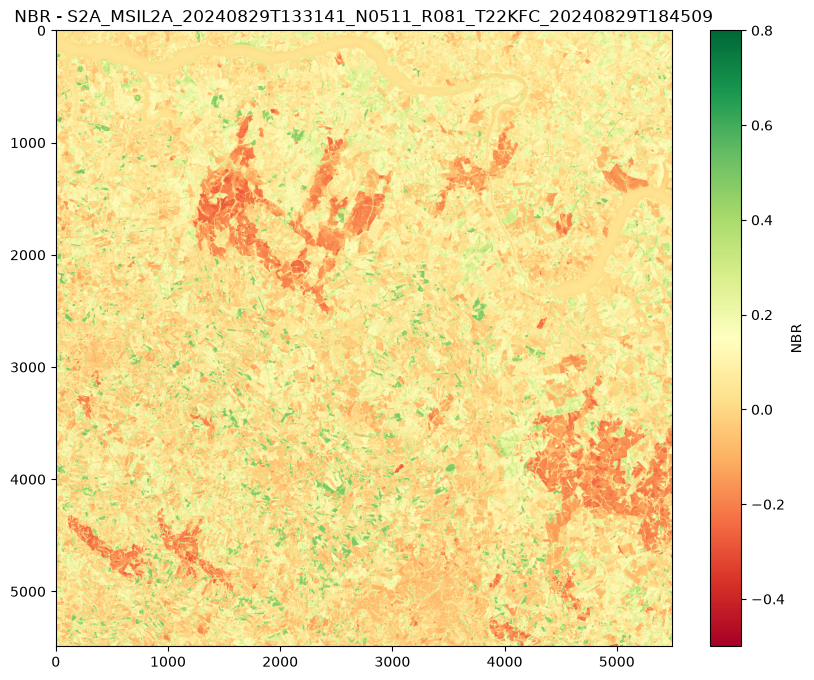

In [35]:
plt.figure(figsize=(10, 8))
# Usando colormapRdYlGn invertido ou YlOrBr (comum para queimadas)
plt.imshow(nbr, cmap="RdYlGn", vmin=-0.5, vmax=0.8)
plt.colorbar(label="NBR")
plt.title(f"NBR - {items[2].id}")
plt.show()


## Gerar a Geometria

#### Pré config

In [36]:
LIMIAR_NBR = -0.15     # Pixels com NBR menor que isso são considerados queimada
TAMANHO_BUFFER = 20    # Raio em metros do buffer quadrado (Sentinel-2 B8A/B12 tem 20m)
UNIR_VIZINHOS = True  

### Filter (Terei que mudar para 1 pois imagem virá com 0 e 1)

In [37]:
linhas, colunas = np.where(nbr < LIMIAR_NBR)
print(f"Pixels detectados como queimada: {len(linhas)}")

Pixels detectados como queimada: 1314684


##### Refs da cena

In [ ]:
transform = profile["transform"]
crs = profile["crs"]

### Gerando geomatrias

In [40]:
lat, long = rio.transform.xy(transform, linhas, colunas, offset="center")
pontos = [Point(x, y) for x, y in zip(lat, long)]

In [41]:
buffers_quadrados = [
    p.buffer(TAMANHO_BUFFER, cap_style="square") for p in pontos
]

In [49]:
if UNIR_VIZINHOS and len(buffers_quadrados) > 0:
    # Une todos os quadrados que se tocam em polígonos
    geometrias_unidas = unary_union(buffers_quadrados)
    
    if geometrias_unidas.geom_type == "MultiPolygon":
        geometrias_finais = list(geometrias_unidas.geoms)
    else:
        geometrias_finais = [geometrias_unidas]
        
    gdf_queimadas = gpd.GeoDataFrame(
        {"id_poligono": range(len(geometrias_finais))},
        geometry=geometrias_finais,
        crs=crs
    )
else:
    gdf_queimadas = gpd.GeoDataFrame(geometry=buffers_quadrados, crs=crs)
# Área Km²
gdf_queimadas["area_km"] = gdf_queimadas.geometry.area / 1e6
print(f"Total de polígonos de queimada gerados: {len(gdf_queimadas)}")
gdf_queimadas.head()


Total de polígonos de queimada gerados: 8334


,id_poligono,geometry,area_km
0,0,"POLYGON ((599990 7690450, 599990 7690470, 5999...",0.0548
1,1,"POLYGON ((601910 7692470, 601910 7692430, 6018...",0.0016
2,2,"POLYGON ((600530 7703750, 600530 7703730, 6005...",0.0148
3,3,"POLYGON ((601450 7707570, 601430 7707570, 6014...",0.0336
4,4,"POLYGON ((601790 7710170, 601790 7710130, 6017...",0.0016


#### View scene

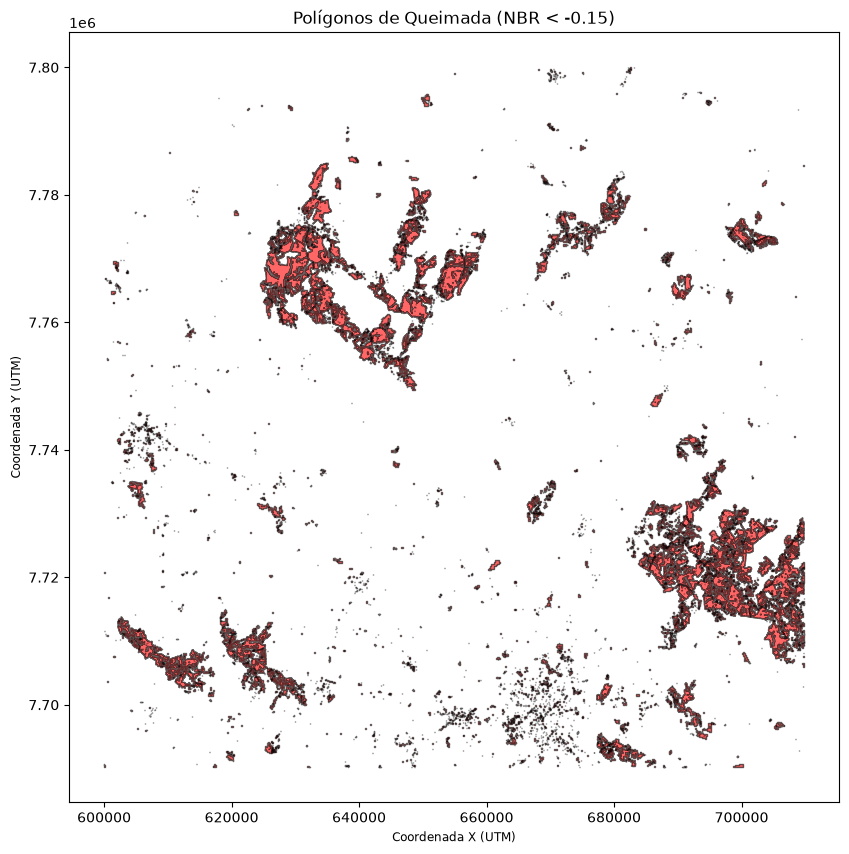

In [46]:

fig, ax = plt.subplots(figsize=(10, 10))
# Plota os polígonos de queimada
gdf_queimadas.plot(ax=ax, color="red", edgecolor="black", alpha=0.6)
ax.set_title(f"Polígonos de Queimada (NBR < {LIMIAR_NBR})")
ax.set_xlabel("Coordenada X (UTM)")
ax.set_ylabel("Coordenada Y (UTM)")
plt.show()

## Save

In [48]:
gdf_queimadas.to_file("poligonos_queimadas_nbr_teste.geojson", driver="GeoJSON")
